# Roman Borders

This file pulls in Maps of Rome

In [1]:
import requests
from pathlib import Path

# ArcGIS Feature Service
base_url = (
    "https://services1.arcgis.com/GWbDzXVIBphv2Dgx/"
    "ArcGIS/rest/services/Roman_Empire_Cultural_Shapefiles/"
    "FeatureServer"
)

# Output directory
output_dir = Path.cwd() / "roman_boundaries"
output_dir.mkdir(exist_ok=True)

# Historical boundary layers
boundary_layers = {
    "roman_60_BC": 26,
    "roman_14_AD": 33,
    "roman_69_AD": 28,
    "roman_117_AD": 35,
    "roman_200_AD": 31,
    "roman_314_AD": 30
}

# Download each boundary
for name, layer_id in boundary_layers.items():

    url = f"{base_url}/{layer_id}/query"

    params = {
        "where": "1=1",
        "outFields": "*",
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson"
    }

    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    # Save GeoJSON
    output_file = output_dir / f"{name}.geojson"

    with open(output_file, "wb") as file:
        file.write(response.content)

    print(f"Downloaded: {output_file}")

Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_60_BC.geojson
Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_14_AD.geojson
Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_69_AD.geojson
Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_117_AD.geojson
Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_200_AD.geojson
Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_314_AD.geojson

In [2]:
# Inspect the metadata for potentially useful historical layers

candidate_layers = [10, 15, 19, 20, 24, 26, 28, 30, 31, 33, 35]

for layer_id in candidate_layers:

    url = f"{base_url}/{layer_id}"

    response = requests.get(
        url,
        params={"f": "json"},
        timeout=60
    )

    response.raise_for_status()
    layer = response.json()

    print("\nLayer:", layer_id)
    print("Name:", layer.get("name"))
    print("Geometry:", layer.get("geometryType"))
    print("Description:", layer.get("description"))
    print("Fields:", [
        field["name"] for field in layer.get("fields", [])
    ])


Layer: 10
Name: Roman_Empire_Around_AD_75
Geometry: esriGeometryPolyline
Description: 
Fields: ['FID', 'Id', 'Shape__Length']

Layer: 15
Name: Provinces Post-Diocletian
Geometry: esriGeometryPolyline
Description: 
Fields: ['FID', 'Id', 'Shape__Length']

Layer: 19
Name: ba_100_prov_boundaries
Geometry: esriGeometryPolyline
Description: 
Fields: ['FID', 'Id', 'Shape__Length']

Layer: 20
Name: ba_100_provinces
Geometry: esriGeometryPolyline
Description: 
Fields: ['FID', 'OBJECTID', 'FNODE_', 'TNODE_', 'LPOLY_', 'RPOLY_', 'LENGTH', 'PROVINCE10', 'PROVINCE_1', 'Shape_Leng', 'Shape__Length']

Layer: 24
Name: temp_conquest
Geometry: esriGeometryPolygon
Description: 
Fields: ['FID', 'Id', 'Shape__Area', 'Shape__Length']

Layer: 26
Name: roman_empire_bc_60_extent
Geometry: esriGeometryPolygon
Description: 
Fields: ['FID', 'OBJECTID', 'AREA', 'PERIMETER', 'NEWDIO_', 'NEWDIO_ID', 'ID', 'Shape_Leng', 'Shape_Area', 'Shape__Area', 'Shape__Length', 'Region_name']

Layer: 28
Name: roman_empire_ad_69_

# Roman Boundary Data Inspection

In [3]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the downloaded boundary files
boundary_dir = Path.cwd() / "roman_boundaries"

# Load each historical boundary
roman_boundaries = {}

for file in boundary_dir.glob("*.geojson"):

    name = file.stem

    gdf = gpd.read_file(file)

    roman_boundaries[name] = gdf

    print(f"\n{name}")
    print("-" * 40)
    print("Features:", len(gdf))
    print("CRS:", gdf.crs)
    print("Geometry types:", gdf.geom_type.value_counts().to_dict())
    print("Columns:", gdf.columns.tolist())



roman_117_AD
----------------------------------------
Features: 112
CRS: EPSG:4326
Geometry types: {'Polygon': 112}
Columns: ['FID', 'OBJECTID', 'AREA', 'PERIMETER', 'NEWDIO_', 'NEWDIO_ID', 'ID', 'Shape_Leng', 'Shape_Area', 'Shape__Area', 'Shape__Length', 'geometry']

roman_133_BC
----------------------------------------
Features: 1
CRS: EPSG:4326
Geometry types: {'MultiPolygon': 1}
Columns: ['date', 'slug', 'label', 'part', 'method', 'area_km2', 'note', 'geometry']

roman_14_AD
----------------------------------------
Features: 109
CRS: EPSG:4326
Geometry types: {'Polygon': 109}
Columns: ['FID', 'OBJECTID', 'AREA', 'PERIMETER', 'NEWDIO_', 'NEWDIO_ID', 'ID', 'Shape_Leng', 'Shape_Area', 'Shape__Area', 'Shape__Length', 'geometry']

roman_200_AD
----------------------------------------
Features: 112
CRS: EPSG:4326
Geometry types: {'Polygon': 112}
Columns: ['FID', 'OBJECTID', 'AREA', 'PERIMETER', 'NEWDIO_', 'NEWDIO_ID', 'ID', 'Shape_Leng', 'Shape_Area', 'Shape__Area', 'Shape__Length', 'ge

## Inspect

In [4]:
# Inspect the 117 AD boundary as an example
empire_117 = roman_boundaries["roman_117_AD"]

# Display the first few records
display(empire_117.head())

# Inspect the geographic extent
print("Geographic bounds:")
print(empire_117.total_bounds)

# Check geometry validity
print("\nInvalid geometries:")
print((~empire_117.geometry.is_valid).sum())

# Check for missing geometries
print("\nMissing geometries:")
print(empire_117.geometry.isna().sum())

Geographic bounds:
[-9.48732 22.89549 43.75164 55.16792]

Invalid geometries:
1

Missing geometries:
0

## Maps

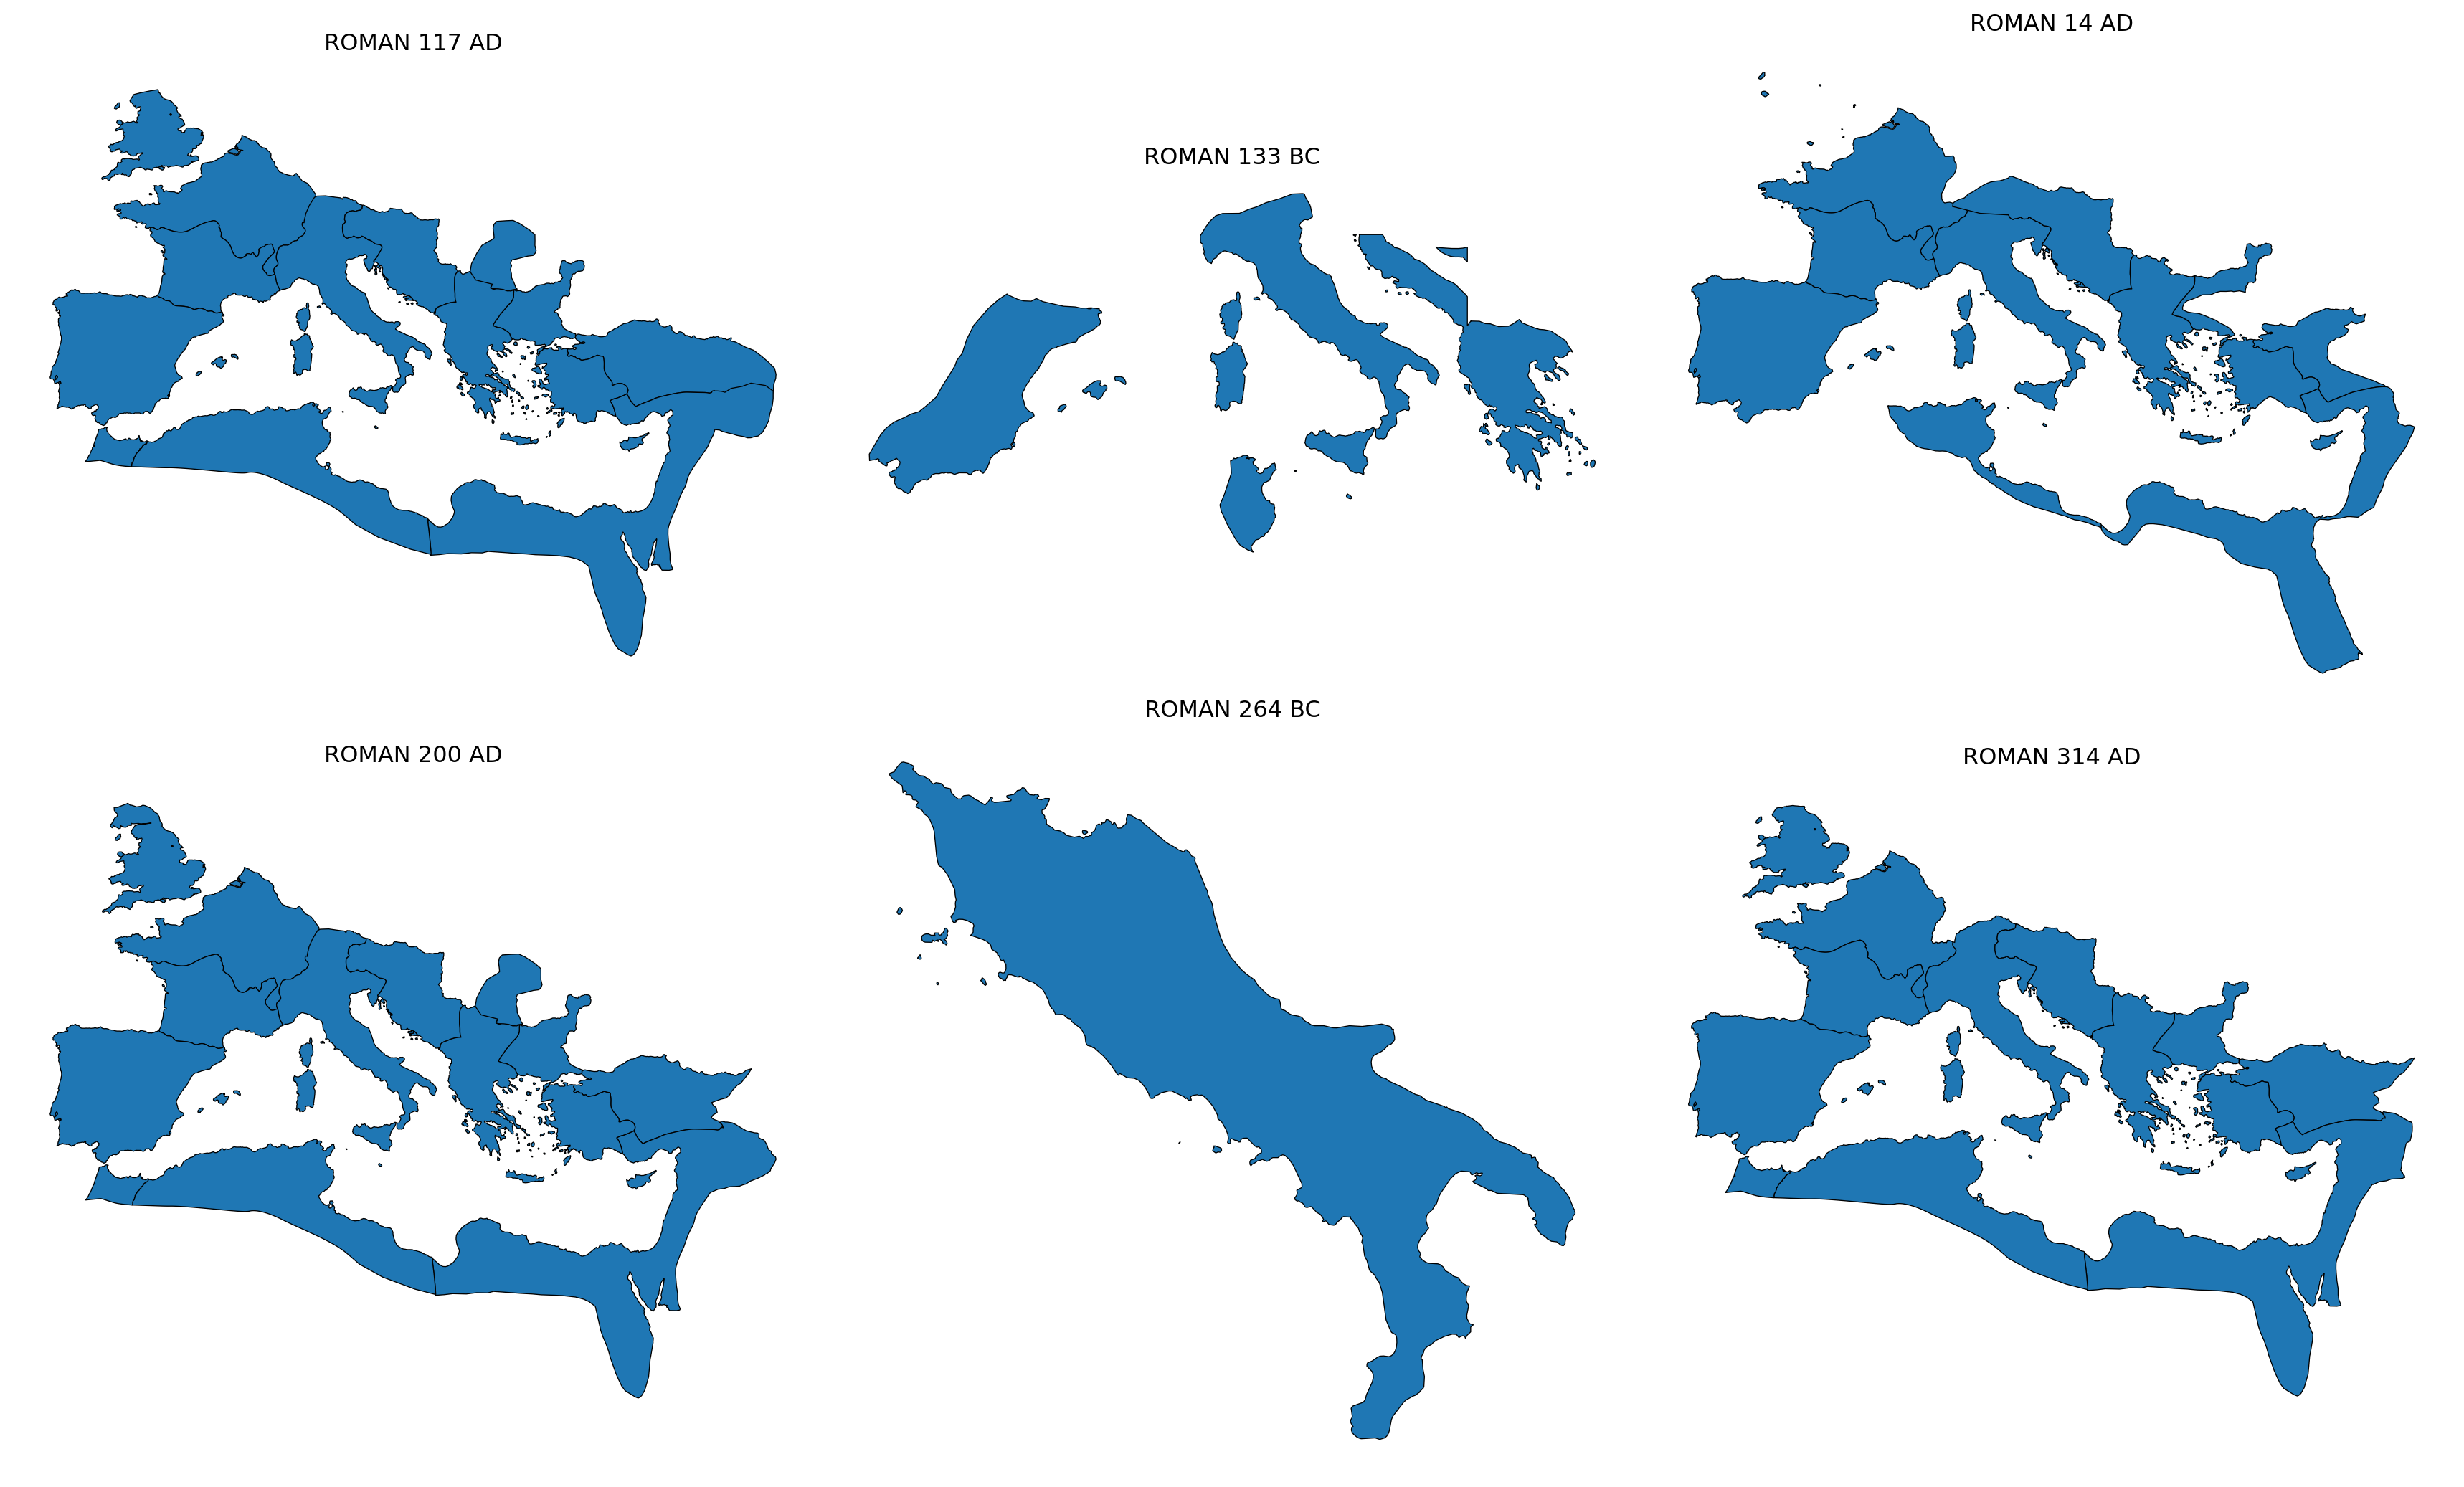

In [5]:
# Create a 2 x 3 grid of maps
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes = axes.flatten()

for ax, (name, gdf) in zip(axes, roman_boundaries.items()):

    gdf.plot(
        ax=ax,
        edgecolor="black",
        linewidth=0.5
    )

    ax.set_title(name.replace("_", " ").upper())
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## Overlapping Borders

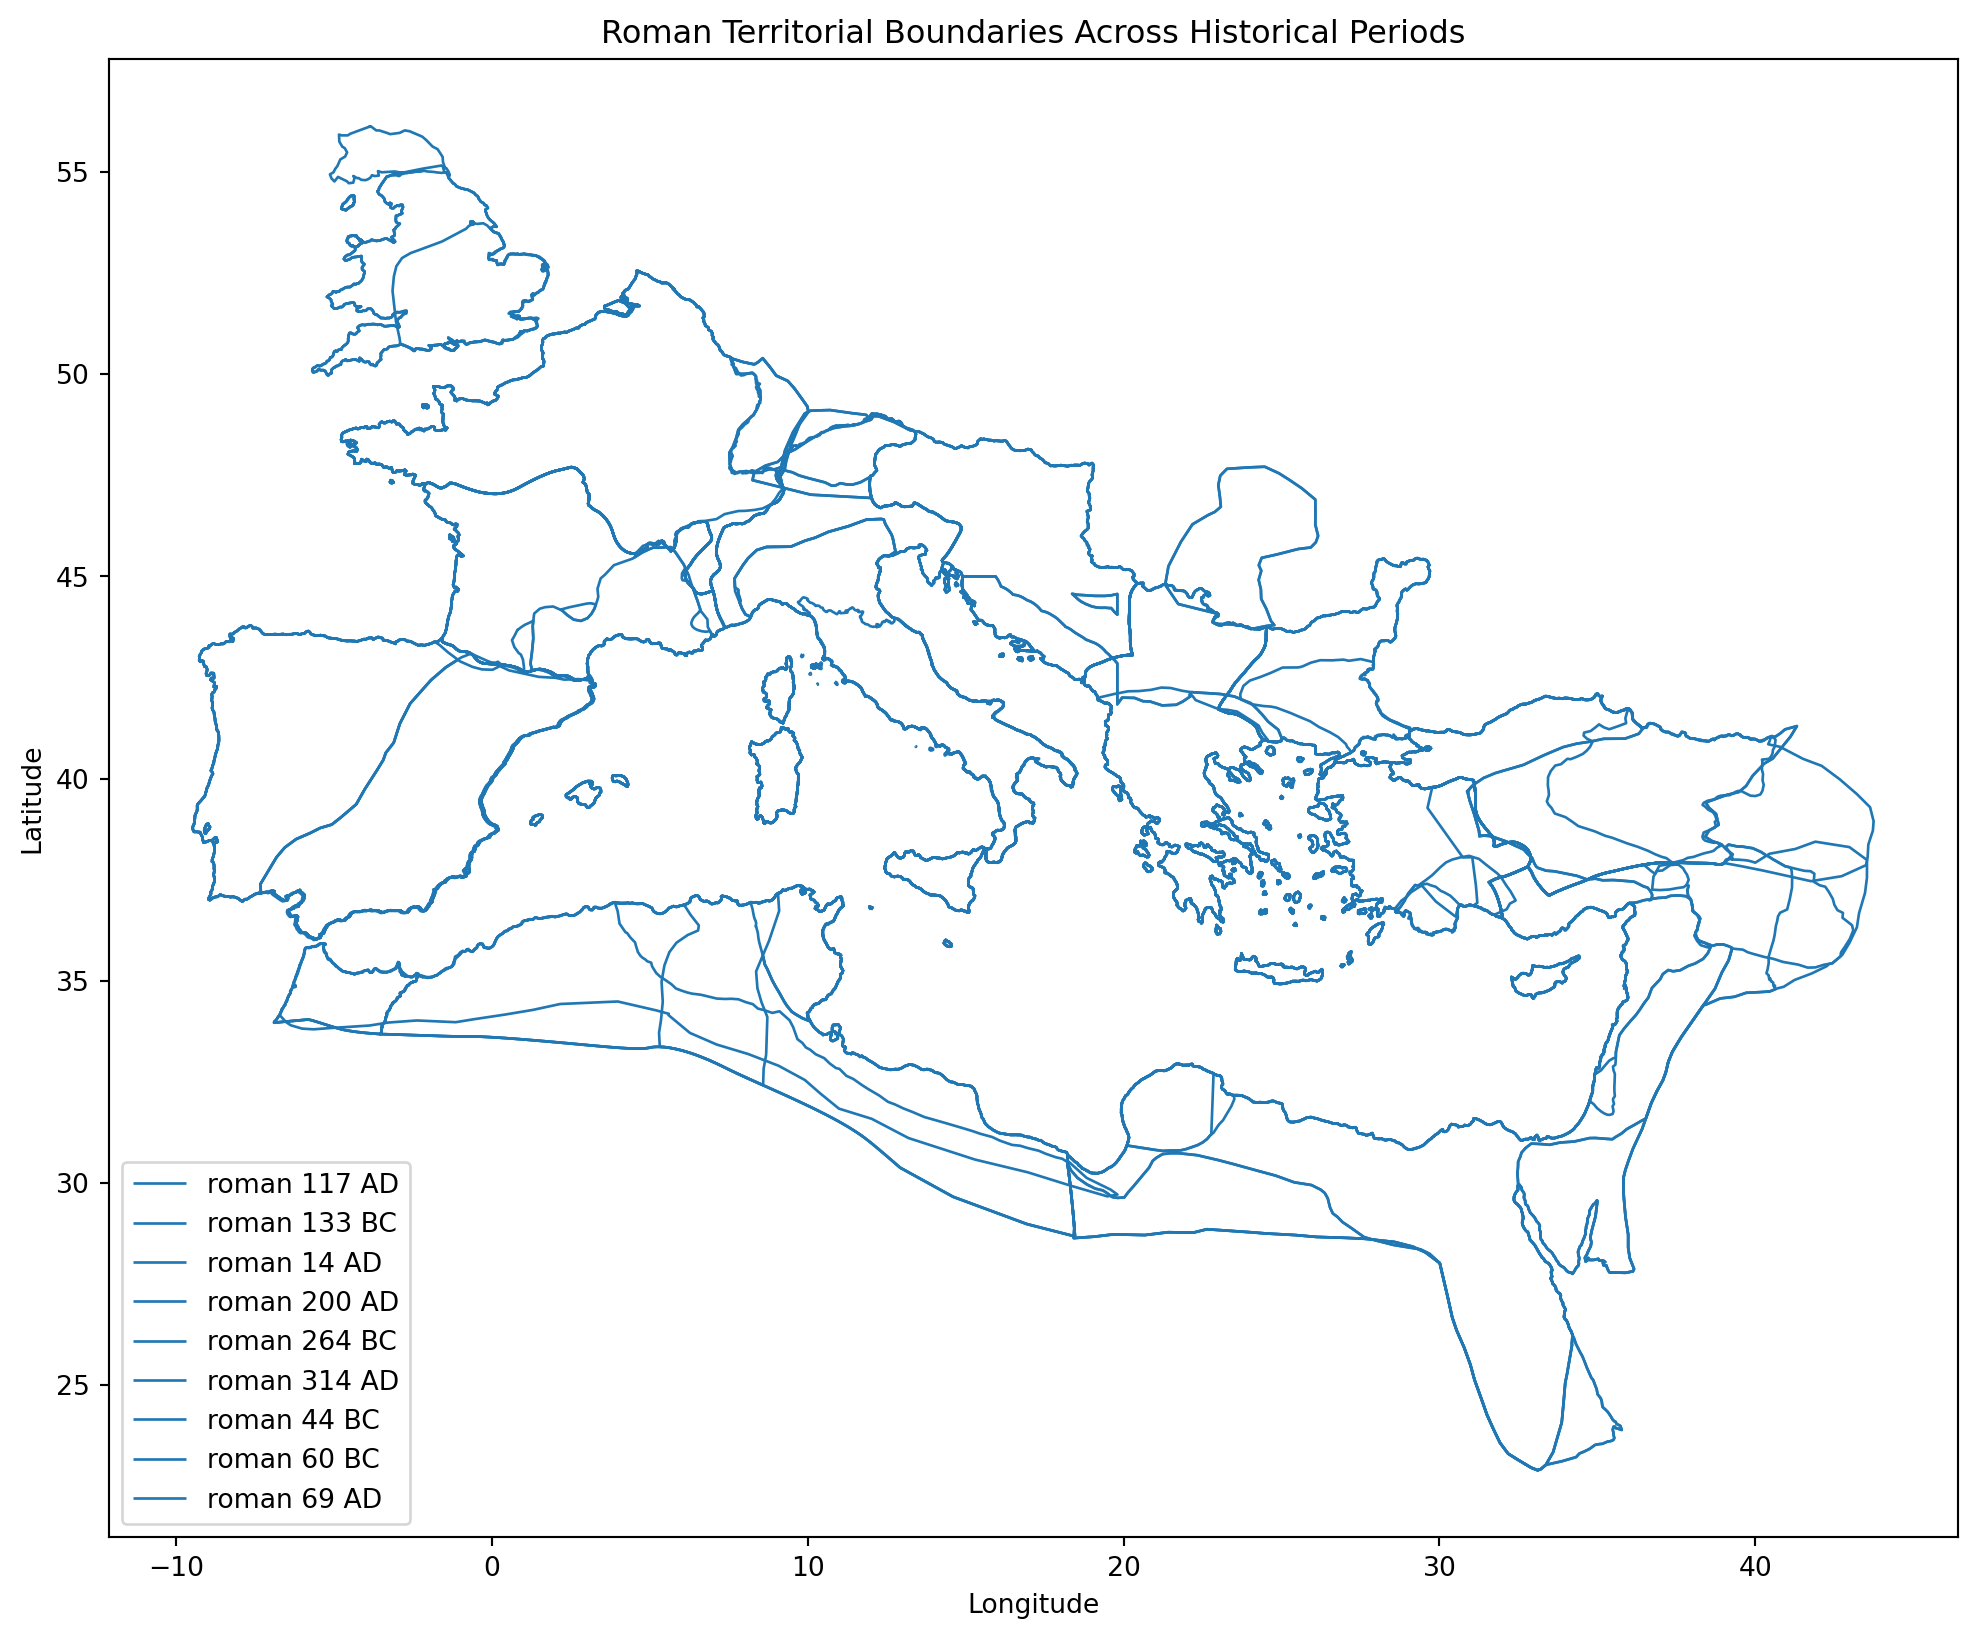

In [6]:
fig, ax = plt.subplots(figsize=(16, 10))

for name, gdf in roman_boundaries.items():

    gdf.boundary.plot(
        ax=ax,
        linewidth=1,
        label=name.replace("_", " ")
    )

ax.set_title("Roman Territorial Boundaries Across Historical Periods")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(loc="lower left")

plt.show()


## Summary

In [7]:
boundary_summary = []

for name, gdf in roman_boundaries.items():

    boundary_summary.append({
        "boundary": name,
        "features": len(gdf),
        "geometry_types": ", ".join(gdf.geom_type.unique()),
        "crs": str(gdf.crs),
        "min_lon": gdf.total_bounds[0],
        "min_lat": gdf.total_bounds[1],
        "max_lon": gdf.total_bounds[2],
        "max_lat": gdf.total_bounds[3],
        "invalid_geometries": int((~gdf.geometry.is_valid).sum())
    })

boundary_summary_df = pd.DataFrame(boundary_summary)

display(boundary_summary_df)

# More Maps “Roman Empire Map”

In [8]:
# Roman Republican Boundaries: Additional Data Source

import json

# Source GeoJSON
source_url = "https://tiles.romanempiremap.com/extents.geojson"

# Save outside the roman_boundaries folder
source_file = Path.cwd() / "roman_empire_map_extents_source.geojson"

# Download source
response = requests.get(source_url, timeout=120)
response.raise_for_status()

# Save original GeoJSON
with open(source_file, "wb") as file:
    file.write(response.content)

print("Downloaded:", source_file)
print("File size:", source_file.stat().st_size, "bytes")


Downloaded: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_empire_map_extents_source.geojson
File size: 1181244 bytes

## Inspect

In [9]:
# Read the original GeoJSON

with open(source_file, "r", encoding="utf-8") as file:
    extent_data = json.load(file)

# Inspect the structure
print("GeoJSON type:", extent_data.get("type"))
print("Total features:", len(extent_data["features"]))

print("\nAvailable property fields:")

print(
    extent_data["features"][0]["properties"].keys()
)

print("\nFirst five features:")

for feature in extent_data["features"][:5]:
    print(feature["properties"])

GeoJSON type: FeatureCollection
Total features: 18

Available property fields:
dict_keys(['date', 'slug', 'label', 'part', 'method', 'area_km2', 'note'])

First five features:
{'date': -753, 'slug': '753-bc', 'label': '753 BC', 'part': 'whole', 'method': 'city', 'area_km2': 7, 'note': 'Symbolic: a circle of 1.5 km radius around the Pleiades location of Rome. The early city is not mapped.'}
{'date': -264, 'slug': '264-bc', 'label': '264 BC', 'part': 'whole', 'method': 'admin1', 'area_km2': 131515, 'note': 'Built from modern Italian provinces (Natural Earth admin-1), so the outline is coarse and follows modern boundaries.'}
{'date': -133, 'slug': '133-bc', 'label': '133 BC', 'part': 'whole', 'method': 'provinces', 'area_km2': 805540, 'note': 'Provinces held at the date (AD 200 AWMC borders), clipped to the AWMC extent for 60 BC. Approximate; Republican control inland was patchy.'}
{'date': -44, 'slug': '44-bc', 'label': '44 BC', 'part': 'whole', 'method': 'provinces', 'area_km2': 1972439

## Load the GeoJSON features into a GeoDataFrame

In [10]:
source_gdf = gpd.read_file(source_file)

print("Total source features:", len(source_gdf))
print("Available dates:", sorted(source_gdf["date"].unique()))

# Select Republican-period boundaries
republican_dates = [-264, -133, -44]

republican_boundaries = source_gdf[
    (source_gdf["date"].isin(republican_dates))
    & (source_gdf["part"] == "whole")
].copy()

# Inspect selected boundaries
display(
    republican_boundaries[
        ["date", "label", "method", "area_km2", "note", "geometry"]
    ]
)

Total source features: 18
Available dates: [np.int32(-753), np.int32(-264), np.int32(-133), np.int32(-44), np.int32(14), np.int32(117), np.int32(211), np.int32(395), np.int32(476), np.int32(565), np.int32(1000), np.int32(1180), np.int32(1453)]

## Save the Maps

In [11]:
# Ensure output directory exists

boundary_dir = Path.cwd() / "roman_boundaries"
boundary_dir.mkdir(exist_ok=True)

# Save each Republican boundary separately

for _, row in republican_boundaries.iterrows():

    # Convert date to filename
    year = abs(int(row["date"]))

    boundary_name = f"roman_{year}_BC"

    # Create a single-feature GeoDataFrame
    boundary_gdf = gpd.GeoDataFrame(
        [row],
        geometry="geometry",
        crs=republican_boundaries.crs
    )

    # Standardize CRS
    boundary_gdf = boundary_gdf.to_crs("EPSG:4326")

    # Save GeoJSON
    output_file = boundary_dir / f"{boundary_name}.geojson"

    boundary_gdf.to_file(
        output_file,
        driver="GeoJSON"
    )

    print("Saved:", output_file)

Saved: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_264_BC.geojson
Saved: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_133_BC.geojson
Saved: C:\Users\PC\code\6750\roman_battles\Datacollection\roman_boundaries\roman_44_BC.geojson

#

In [12]:
# Load all historical boundaries

roman_boundaries = {}

for file in boundary_dir.glob("*.geojson"):

    name = file.stem

    gdf = gpd.read_file(file)

    roman_boundaries[name] = gdf

    print(
        name,
        "| Features:", len(gdf),
        "| CRS:", gdf.crs,
        "| Geometry:", gdf.geom_type.unique()
    )

roman_117_AD | Features: 112 | CRS: EPSG:4326 | Geometry: ['Polygon']
roman_133_BC | Features: 1 | CRS: EPSG:4326 | Geometry: ['MultiPolygon']
roman_14_AD | Features: 109 | CRS: EPSG:4326 | Geometry: ['Polygon']
roman_200_AD | Features: 112 | CRS: EPSG:4326 | Geometry: ['Polygon']
roman_264_BC | Features: 1 | CRS: EPSG:4326 | Geometry: ['MultiPolygon']
roman_314_AD | Features: 111 | CRS: EPSG:4326 | Geometry: ['Polygon']
roman_44_BC | Features: 1 | CRS: EPSG:4326 | Geometry: ['MultiPolygon']
roman_60_BC | Features: 74 | CRS: EPSG:4326 | Geometry: ['Polygon']
roman_69_AD | Features: 110 | CRS: EPSG:4326 | Geometry: ['Polygon']

# Final Maps

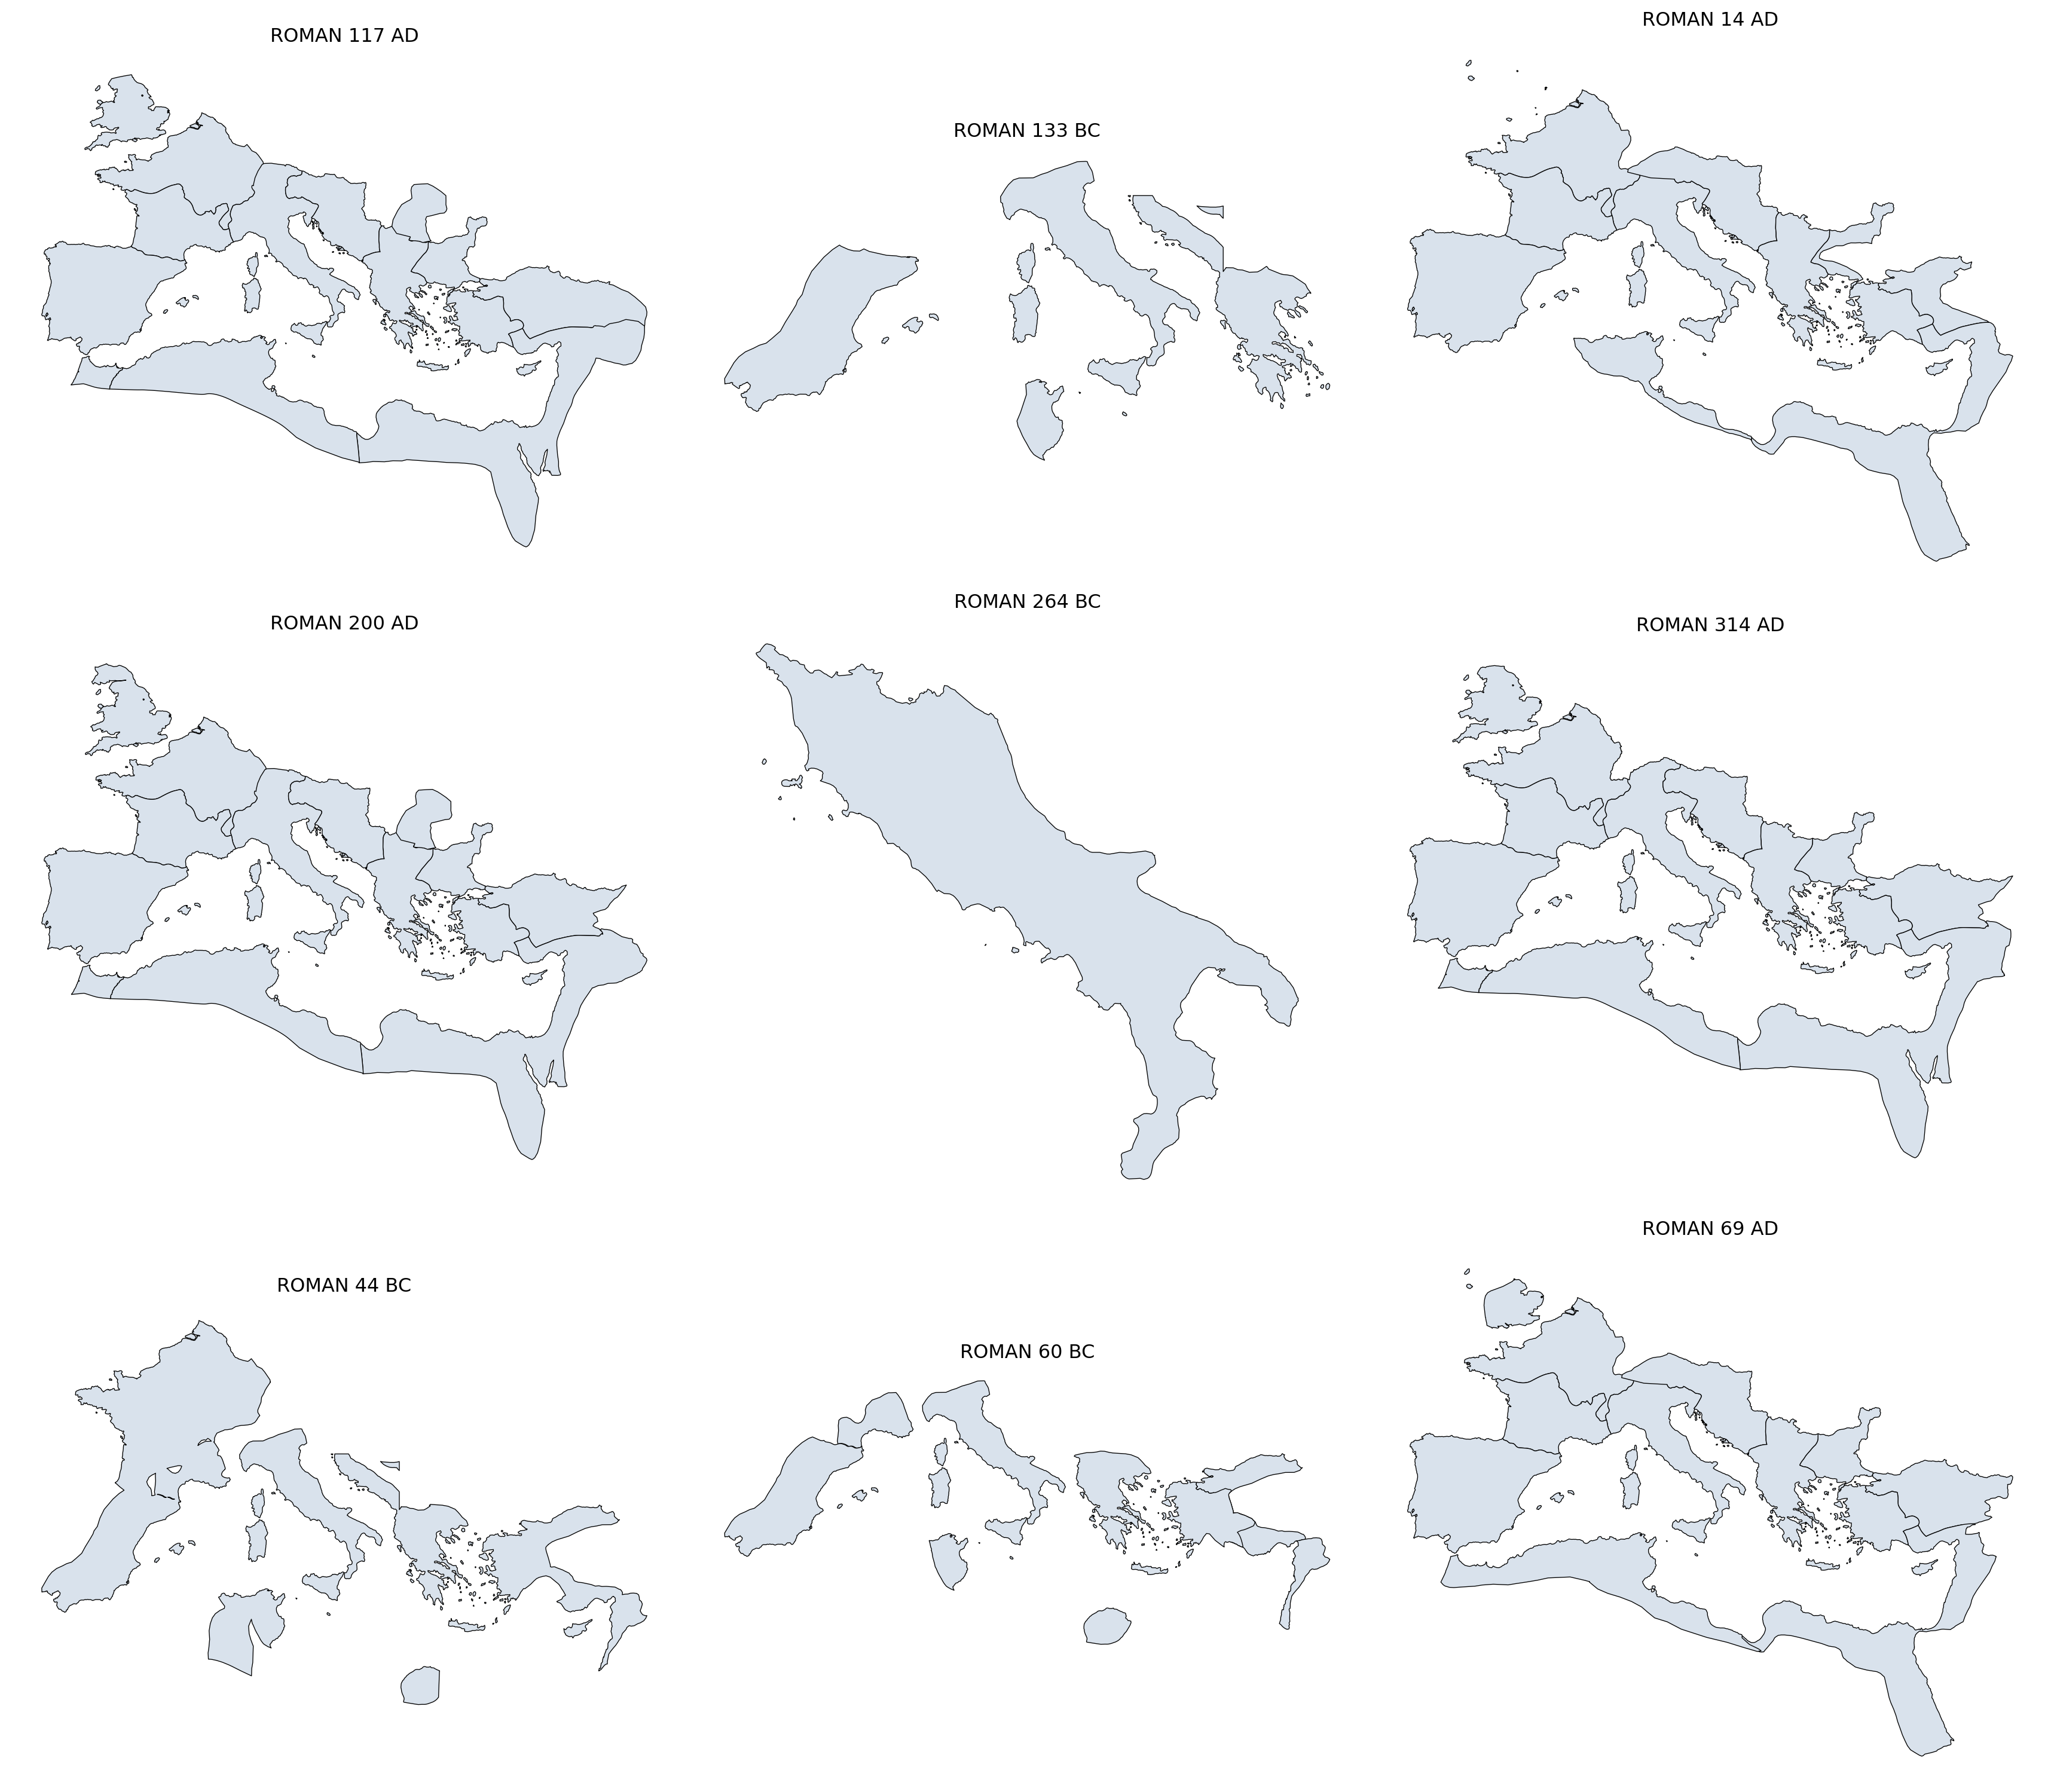

In [13]:
# Create a 3 x 3 grid of maps
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

axes = axes.flatten()

for ax, (name, gdf) in zip(axes, roman_boundaries.items()):

    gdf.plot(
        ax=ax,
        edgecolor="black",
        linewidth=0.5,
        facecolor="#D9E2EC"
    )

    ax.set_title(name.replace("_", " ").upper())
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## Overlapping Borders

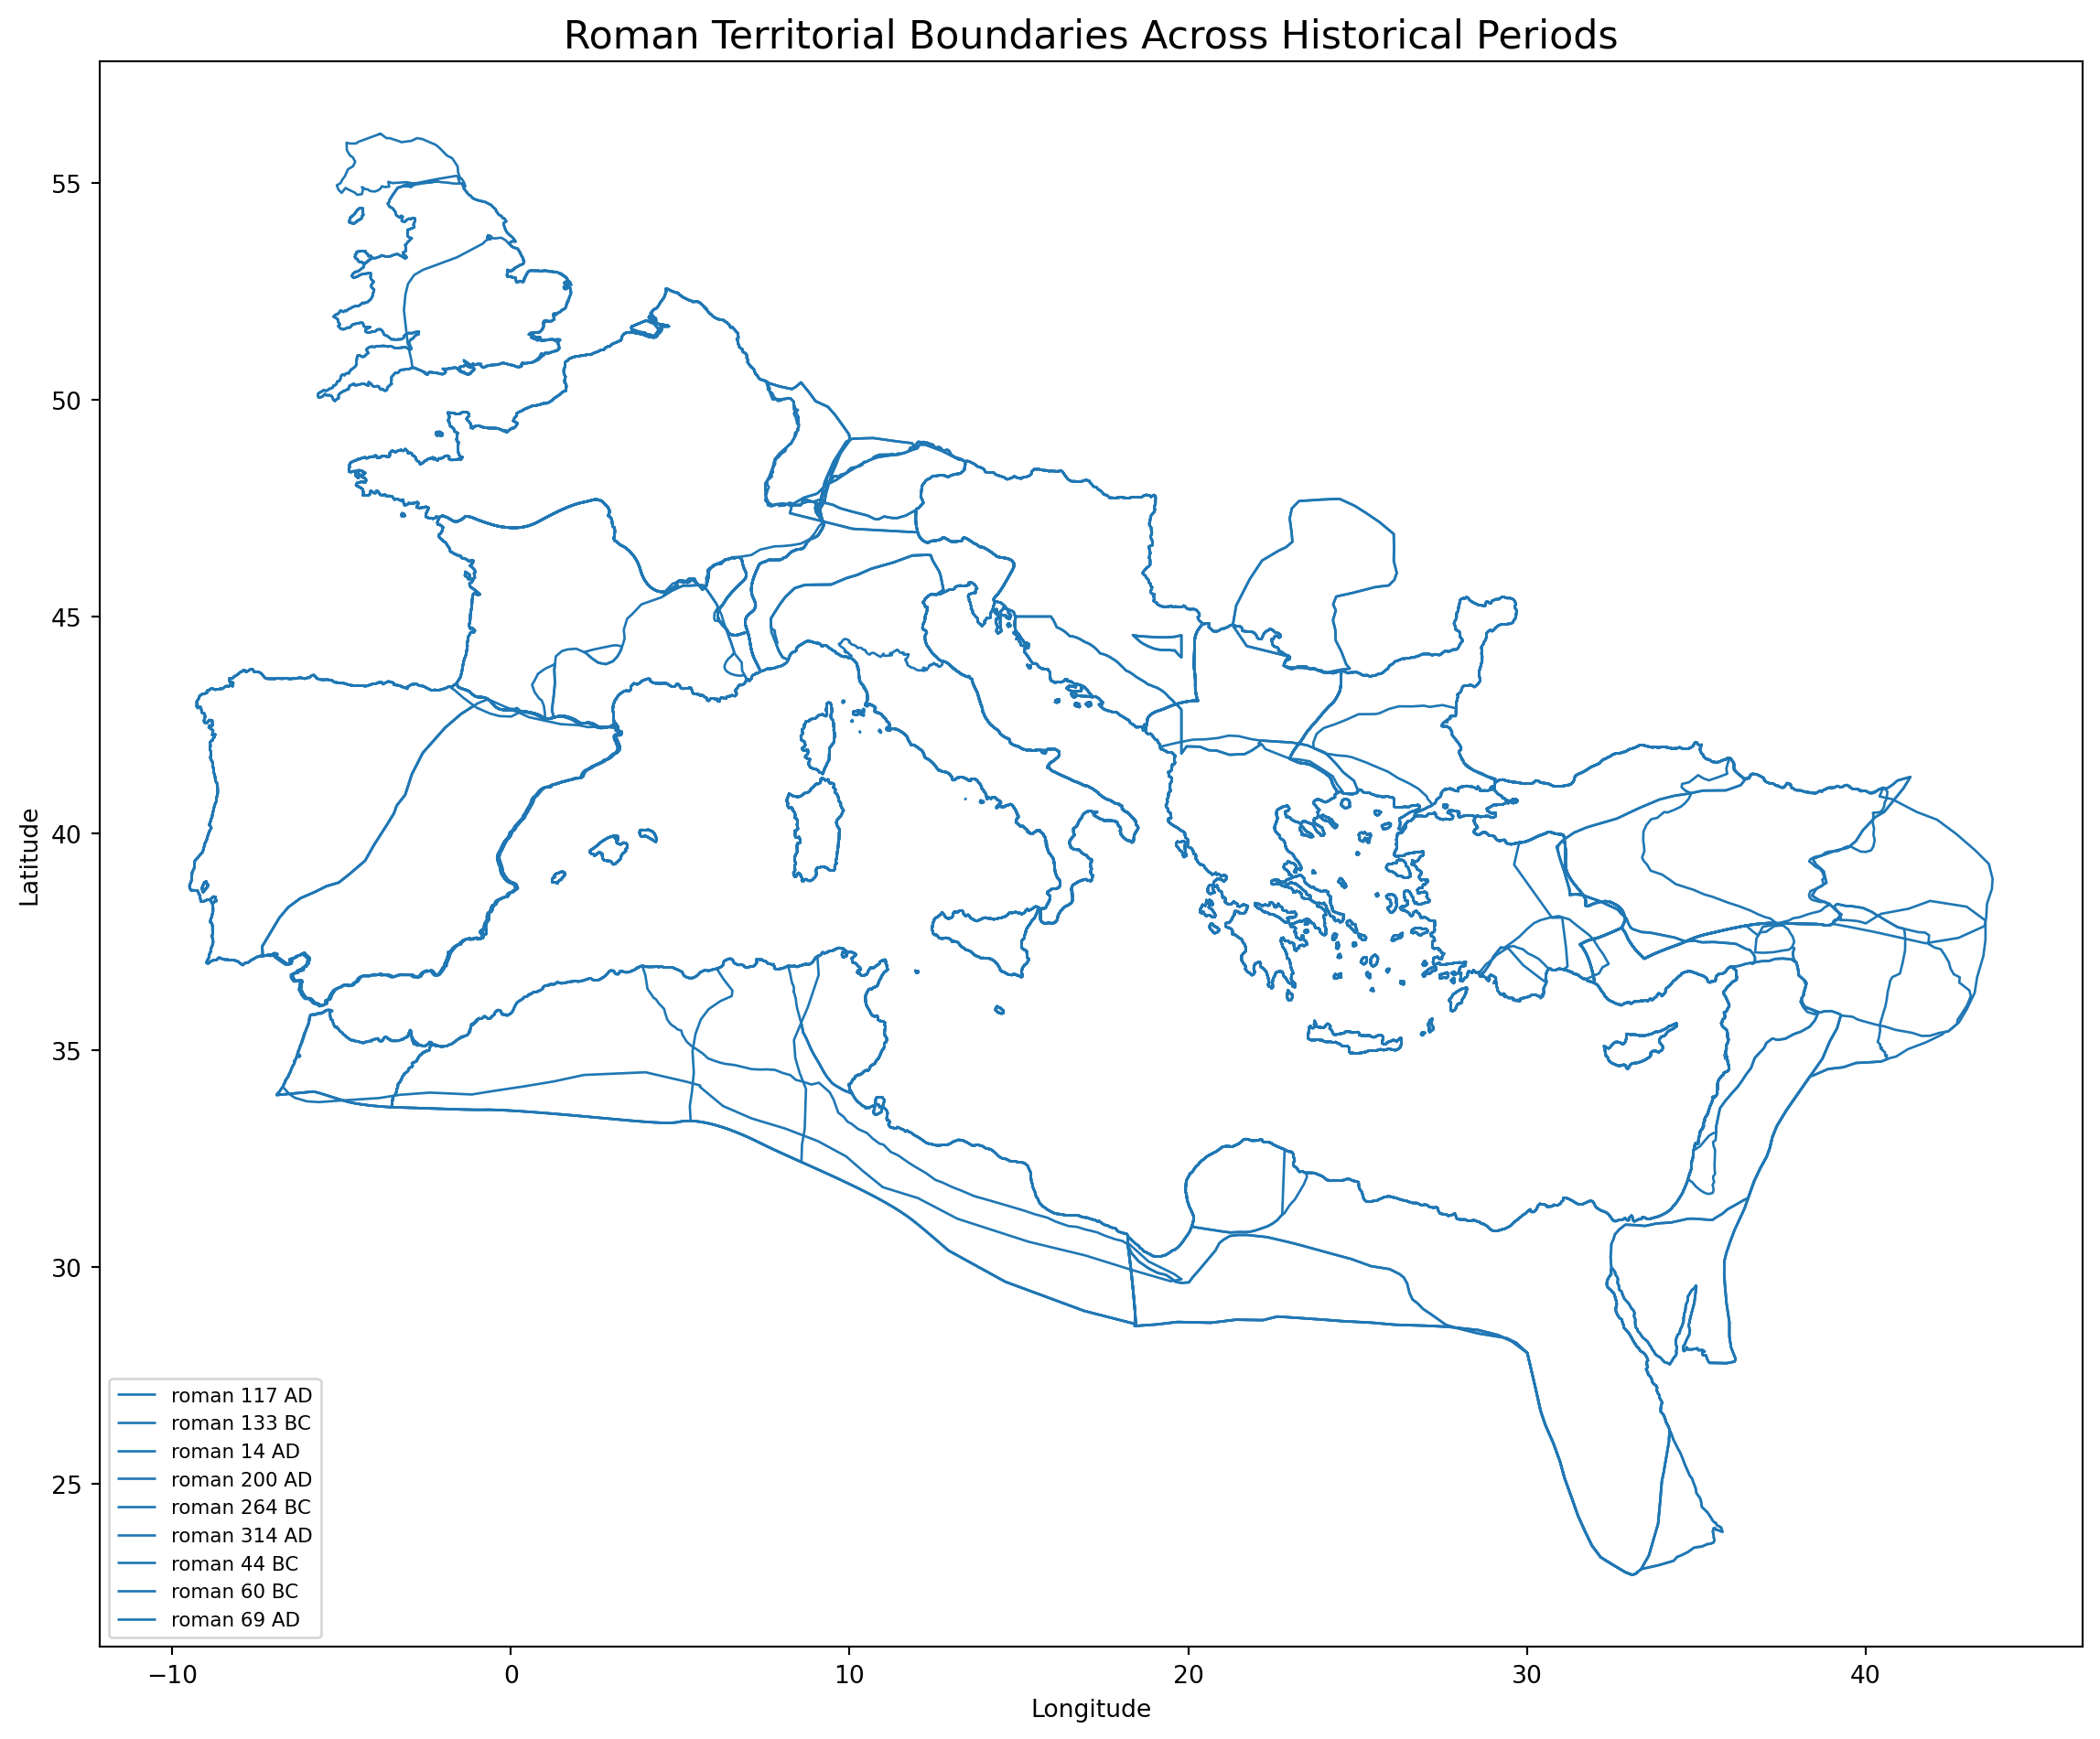

In [14]:
fig, ax = plt.subplots(figsize=(16, 10))

for name, gdf in roman_boundaries.items():

    gdf.boundary.plot(
        ax=ax,
        linewidth=1,
        label=name.replace("_", " ")
    )

ax.set_title(
    "Roman Territorial Boundaries Across Historical Periods",
    fontsize=16
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.legend(
    loc="lower left",
    fontsize=8
)

plt.tight_layout()
plt.show()